<a href="https://colab.research.google.com/github/leandrom88/tesis-restauracion-imagenes/blob/main/notebooks_03_prototipo_pix2pix.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import os
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torchvision.transforms as T
from google.colab import drive

# 1. Montar Google Drive
drive.mount('/content/drive')

# 2. Definición directa del Dataset y DataLoader
class FachadasDataset(Dataset):
    def __init__(self, raiz_split, tamano=(512, 512),
                 prompt="A high-resolution photograph of a restored historic architectural building facade, clean masonry"):
        self.dir_source = os.path.join(raiz_split, 'source')
        self.dir_target = os.path.join(raiz_split, 'target')

        exts = ('.jpg', '.jpeg', '.png', '.bmp')
        self.archivos = sorted([
            f for f in os.listdir(self.dir_source)
            if f.lower().endswith(exts)
        ])
        self.prompt = prompt

        self.transform = T.Compose([
            T.Resize(tamano),
            T.CenterCrop(tamano),
            T.ToTensor(),
            T.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
        ])

    def __len__(self):
        return len(self.archivos)

    def __getitem__(self, idx):
        nombre_archivo = self.archivos[idx]
        ruta_source = os.path.join(self.dir_source, nombre_archivo)
        ruta_target = os.path.join(self.dir_target, nombre_archivo)

        img_source = Image.open(ruta_source).convert('RGB')
        img_target = Image.open(ruta_target).convert('RGB')

        return {
            "source": self.transform(img_source),
            "target": self.transform(img_target),
            "prompt": self.prompt,
            "filename": nombre_archivo
        }

def obtener_dataloader(raiz_split, batch_size=4, shuffle=True, tamano=(512, 512), num_workers=0):
    dataset = FachadasDataset(raiz_split=raiz_split, tamano=tamano)
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=num_workers,
        pin_memory=True
    )

# 3. Selección de dispositivo de cómputo
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"✅ Dispositivo activo: {device}")

# 4. Instanciar DataLoader de entrenamiento
RUTA_PROCESSED = '/content/drive/MyDrive/dataset_processed_80_10_10'
train_loader = obtener_dataloader(
    raiz_split=os.path.join(RUTA_PROCESSED, 'train'),
    batch_size=4,
    shuffle=True,
    tamano=(512, 512),
    num_workers=2
)
print(f"🚀 Lotes listos: {len(train_loader)} por época.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Dispositivo activo: cuda
🚀 Lotes listos: 272 por época.


In [4]:
# ==============================================================================
# GENERADOR U-NET (512x512)
# ==============================================================================
class BloqueDown(nn.Module):
    def __init__(self, in_c, out_c, normalize=True, dropout=0.0):
        super().__init__()
        capas = [nn.Conv2d(in_c, out_c, kernel_size=4, stride=2, padding=1, bias=False)]
        if normalize:
            capas.append(nn.BatchNorm2d(out_c))
        capas.append(nn.LeakyReLU(0.2, inplace=True))
        if dropout > 0.0:
            capas.append(nn.Dropout(dropout))
        self.bloque = nn.Sequential(*capas)

    def forward(self, x):
        return self.bloque(x)

class BloqueUp(nn.Module):
    def __init__(self, in_c, out_c, dropout=0.0):
        super().__init__()
        capas = [
            nn.ConvTranspose2d(in_c, out_c, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True)
        ]
        if dropout > 0.0:
            capas.append(nn.Dropout(dropout))
        self.bloque = nn.Sequential(*capas)

    def forward(self, x, skip):
        x = self.bloque(x)
        return torch.cat([x, skip], dim=1)

class GeneradorUNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=3):
        super().__init__()
        # Encoder (Downsampling de 512 a 2)
        self.d1 = BloqueDown(in_channels, 64, normalize=False)  # 512 -> 256
        self.d2 = BloqueDown(64, 128)                           # 256 -> 128
        self.d3 = BloqueDown(128, 256)                          # 128 -> 64
        self.d4 = BloqueDown(256, 512)                          # 64 -> 32
        self.d5 = BloqueDown(512, 512)                          # 32 -> 16
        self.d6 = BloqueDown(512, 512)                          # 16 -> 8
        self.d7 = BloqueDown(512, 512)                          # 8 -> 4
        self.d8 = BloqueDown(512, 512, normalize=False)         # 4 -> 2

        # Decoder (Upsampling con Skip Connections)
        self.u1 = BloqueUp(512, 512, dropout=0.5)               # 2 -> 4
        self.u2 = BloqueUp(1024, 512, dropout=0.5)              # 4 -> 8
        self.u3 = BloqueUp(1024, 512, dropout=0.5)              # 8 -> 16
        self.u4 = BloqueUp(1024, 512)                           # 16 -> 32
        self.u5 = BloqueUp(1024, 256)                           # 32 -> 64
        self.u6 = BloqueUp(512, 128)                            # 64 -> 128
        self.u7 = BloqueUp(256, 64)                             # 128 -> 256

        self.salida = nn.Sequential(
            nn.ConvTranspose2d(128, out_channels, kernel_size=4, stride=2, padding=1), # 256 -> 512
            nn.Tanh()
        )

    def forward(self, x):
        d1 = self.d1(x)
        d2 = self.d2(d1)
        d3 = self.d3(d2)
        d4 = self.d4(d3)
        d5 = self.d5(d4)
        d6 = self.d6(d5)
        d7 = self.d7(d6)
        d8 = self.d8(d7)

        u1 = self.u1(d8, d7)
        u2 = self.u2(u1, d6)
        u3 = self.u3(u2, d5)
        u4 = self.u4(u3, d4)
        u5 = self.u5(u4, d3)
        u6 = self.u6(u5, d2)
        u7 = self.u7(u6, d1)
        return self.salida(u7)

# ==============================================================================
# DISCRIMINADOR PATCHGAN (70x70)
# ==============================================================================
class DiscriminadorPatchGAN(nn.Module):
    def __init__(self, in_channels=6): # 3 canales input + 3 canales target concatenados
        super().__init__()
        def bloque(in_c, out_c, stride=2, normalize=True):
            capas = [nn.Conv2d(in_c, out_c, 4, stride=stride, padding=1, bias=False)]
            if normalize:
                capas.append(nn.BatchNorm2d(out_c))
            capas.append(nn.LeakyReLU(0.2, inplace=True))
            return capas

        self.modelo = nn.Sequential(
            *bloque(in_channels, 64, normalize=False),
            *bloque(64, 128),
            *bloque(128, 256),
            *bloque(256, 512, stride=1),
            nn.Conv2d(512, 1, 4, stride=1, padding=1)
        )

    def forward(self, x_cond, y_target):
        entrada_concatenada = torch.cat([x_cond, y_target], dim=1)
        return self.modelo(entrada_concatenada)

netG = GeneradorUNet().to(device)
netD = DiscriminadorPatchGAN().to(device)
print("Modelos instanciados en memoria.")

Modelos instanciados en memoria.


In [5]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.utils as vutils

# Criterios y optimizadores estándar de Pix2Pix
criterion_GAN = nn.BCEWithLogitsLoss()
criterion_pixelwise = nn.L1Loss()
LAMBDA_L1 = 100.0

optimizer_G = optim.Adam(netG.parameters(), lr=0.0002, betas=(0.5, 0.999))
optimizer_D = optim.Adam(netD.parameters(), lr=0.0002, betas=(0.5, 0.999))

NUM_EPOCHS = 1  # 1 época inicial para verificar funcionamiento completo
os.makedirs("salidas_muestras", exist_ok=True)
os.makedirs("checkpoints_pix2pix", exist_ok=True)

print("🚀 Iniciando entrenamiento base...")
for epoch in range(1, NUM_EPOCHS + 1):
    for i, batch in enumerate(train_loader):
        real_A = batch["source"].to(device)  # Degradada (Condición)
        real_B = batch["target"].to(device)  # Limpia (Target)

        # -----------------------------
        #  1. Entrenar el Generador
        # -----------------------------
        optimizer_G.zero_grad()
        fake_B = netG(real_A)
        pred_fake = netD(real_A, fake_B)

        loss_GAN = criterion_GAN(pred_fake, torch.ones_like(pred_fake))
        loss_pixel = criterion_pixelwise(fake_B, real_B)
        loss_G = loss_GAN + (LAMBDA_L1 * loss_pixel)
        loss_G.backward()
        optimizer_G.step()

        # -----------------------------
        #  2. Entrenar el Discriminador
        # -----------------------------
        optimizer_D.zero_grad()
        pred_real = netD(real_A, real_B)
        loss_real = criterion_GAN(pred_real, torch.ones_like(pred_real))

        pred_fake = netD(real_A, fake_B.detach())
        loss_fake = criterion_GAN(pred_fake, torch.zeros_like(pred_fake))

        loss_D = 0.5 * (loss_real + loss_fake)
        loss_D.backward()
        optimizer_D.step()

        if i % 10 == 0:
            print(f"[Época {epoch}/{NUM_EPOCHS}] [Batch {i}/{len(train_loader)}] "
                  f"Loss D: {loss_D.item():.4f} | Loss G: {loss_G.item():.4f} (L1: {loss_pixel.item():.4f})")

    # Guardar muestra visual comparativa al cierre de la época (desnormalizada a [0, 1])
    img_comparativa = torch.cat([real_A[0:1], fake_B[0:1], real_B[0:1]], dim=0)
    img_comparativa = (img_comparativa + 1.0) / 2.0
    vutils.save_image(img_comparativa, f"salidas_muestras/epoca_{epoch}.png")

# Guardar pesos finales del prototipo
torch.save(netG.state_dict(), "checkpoints_pix2pix/netG_baseline.pth")
torch.save(netD.state_dict(), "checkpoints_pix2pix/netD_baseline.pth")
print("✅ Entrenamiento completado y checkpoints guardados.")

🚀 Iniciando entrenamiento base...
[Época 1/1] [Batch 0/272] Loss D: 0.7084 | Loss G: 63.0590 (L1: 0.6239)
[Época 1/1] [Batch 10/272] Loss D: 0.6772 | Loss G: 28.8742 (L1: 0.2811)
[Época 1/1] [Batch 20/272] Loss D: 0.6460 | Loss G: 24.4385 (L1: 0.2353)
[Época 1/1] [Batch 30/272] Loss D: 0.5424 | Loss G: 15.5054 (L1: 0.1469)
[Época 1/1] [Batch 40/272] Loss D: 0.6903 | Loss G: 14.9368 (L1: 0.1415)
[Época 1/1] [Batch 50/272] Loss D: 0.6504 | Loss G: 24.0139 (L1: 0.2325)
[Época 1/1] [Batch 60/272] Loss D: 0.6190 | Loss G: 22.7647 (L1: 0.2179)
[Época 1/1] [Batch 70/272] Loss D: 0.6380 | Loss G: 19.1628 (L1: 0.1838)
[Época 1/1] [Batch 80/272] Loss D: 0.6612 | Loss G: 11.4630 (L1: 0.1067)
[Época 1/1] [Batch 90/272] Loss D: 0.6917 | Loss G: 19.6805 (L1: 0.1892)
[Época 1/1] [Batch 100/272] Loss D: 0.6113 | Loss G: 14.2134 (L1: 0.1339)
[Época 1/1] [Batch 110/272] Loss D: 0.6282 | Loss G: 13.3316 (L1: 0.1264)
[Época 1/1] [Batch 120/272] Loss D: 0.6239 | Loss G: 25.0432 (L1: 0.2382)
[Época 1/1] [Ba

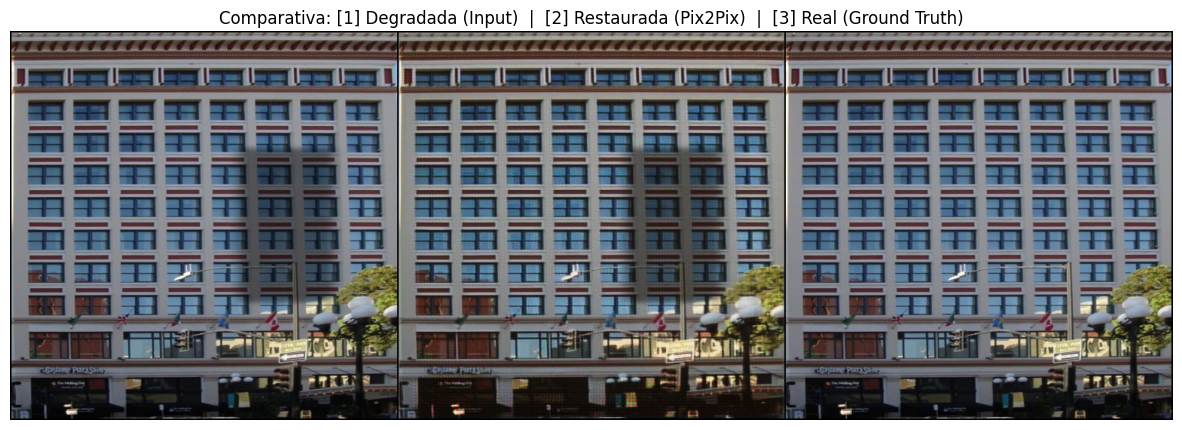

In [6]:
import matplotlib.pyplot as plt
from PIL import Image

# Cargar la imagen comparativa generada (Degradada | Restaurada | Limpia Real)
img_sample = Image.open("salidas_muestras/epoca_1.png")

plt.figure(figsize=(15, 6))
plt.imshow(img_sample)
plt.title("Comparativa: [1] Degradada (Input)  |  [2] Restaurada (Pix2Pix)  |  [3] Real (Ground Truth)")
plt.axis("off")
plt.show()

In [7]:
import shutil

# Crear carpeta de respaldo en Drive y copiar los pesos entrenados
RUTA_DESTINO_DRIVE = "/content/drive/MyDrive/checkpoints_pix2pix"
os.makedirs(RUTA_DESTINO_DRIVE, exist_ok=True)

shutil.copy("checkpoints_pix2pix/netG_baseline.pth", os.path.join(RUTA_DESTINO_DRIVE, "netG_baseline.pth"))
shutil.copy("checkpoints_pix2pix/netD_baseline.pth", os.path.join(RUTA_DESTINO_DRIVE, "netD_baseline.pth"))
shutil.copy("salidas_muestras/epoca_1.png", os.path.join(RUTA_DESTINO_DRIVE, "muestra_epoca_1.png"))

print("✅ Pesos y muestras respaldados en Google Drive.")

✅ Pesos y muestras respaldados en Google Drive.
